In [1]:
from climada_petals.hazard import TCForecast
import logging
import datetime
import os
import numpy as np
import geopandas as gpd
import pickle

In [2]:
### impacts calculated
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/imph2.pkl', 'rb') as file:
    imph2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/ed2.pkl', 'rb') as file:
    ed2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/mimpacts_all.pkl', 'rb') as file:
    mimpacts_all = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/exp_dict.pkl', 'rb') as file:
    exp_dict = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/ens_variables.pkl', 'rb') as file:
    ens_variables = pickle.load(file)

In [3]:
###SUBNATIONAL DIVISION 
import geopandas as gpd
geofile_MOZ = '/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ/gadm41_MOZ_shp/gadm41_MOZ_1.shp'
gadm_MOZ = gpd.read_file(geofile_MOZ)

In [4]:
## DATAFRAMES OF THE IMPACTS AND CONVERTING EXPOSURES TO DATAFRAMES DICTIONARIES
import pandas as pd
import numpy as np
import copy
from climada.entity import Exposures


# Your impact data
# ... [mimpacts_all definition, assumed to be defined above]
### THIS exp_df_fict is important to join it with the impact data that I am extracting from 
## here from mimpacts_all. In the last step I am converting exposures to dataframes to join it 
## with the impact values, which is important afterwards to join_dfs (data with mean impact plus
## exposure) 

# Converting the impact data into DataFrames
imp_df = {}  # A dictionary to store the impact data DataFrames

for imp_key, impacts in mimpacts_all.items():
    imp_df[imp_key] = pd.DataFrame.from_dict(impacts, orient='index').T

# Converting Exposure objects to DataFrames and saving in a new dictionary
exp_df_dict = {f"{key}_df": pd.DataFrame(copy.deepcopy(exp.gdf)) for key, exp in exp_dict.items()}

In [5]:
import geopandas as gpd

joined_dfs = {}

print("Keys in exp_df_dict:", exp_df_dict.keys())
print("Keys in imp_df:", imp_df.keys())

for prefix in [('exp_h', 'imph'), ('exp_ed','ed'),('exp_rd','rd'),('exp_pp', 'impp')]:
    for i in range(1, 9):  
        exp_key = f'{prefix[0]}{i}_MOZ_df'
        imp_key = f'{prefix[1]}{i}'
        
        print(f"Checking for keys: {exp_key}, {imp_key}")
        
        if exp_key in exp_df_dict and imp_key in imp_df:
            exp_reset = exp_df_dict[exp_key].reset_index(drop=True)
            imp_reset = imp_df[imp_key].reset_index(drop=True)
            
            if exp_reset.shape[0] != imp_reset.shape[0]:
                print(f"Number of rows does not match for {exp_key} and {imp_key}. Skipping.")
                continue
            
            joined_dfs[imp_key] = pd.concat([exp_reset, imp_reset], axis=1) 

Keys in exp_df_dict: dict_keys(['exp_h1_MOZ_df', 'exp_ed1_MOZ_df', 'exp_rd1_MOZ_df', 'exp_pp1_MOZ_df', 'exp_h2_MOZ_df', 'exp_ed2_MOZ_df', 'exp_rd2_MOZ_df', 'exp_pp2_MOZ_df', 'exp_pp3_MOZ_df', 'exp_pp4_MOZ_df', 'exp_pp5_MOZ_df', 'exp_pp6_MOZ_df', 'exp_pp7_MOZ_df', 'exp_pp8_MOZ_df'])
Keys in imp_df: dict_keys(['imph1', 'imph2', 'ed1', 'ed2', 'rd1', 'rd2', 'impp1', 'impp2', 'impp5', 'impp6'])
Checking for keys: exp_h1_MOZ_df, imph1
Checking for keys: exp_h2_MOZ_df, imph2
Checking for keys: exp_h3_MOZ_df, imph3
Checking for keys: exp_h4_MOZ_df, imph4
Checking for keys: exp_h5_MOZ_df, imph5
Checking for keys: exp_h6_MOZ_df, imph6
Checking for keys: exp_h7_MOZ_df, imph7
Checking for keys: exp_h8_MOZ_df, imph8
Checking for keys: exp_ed1_MOZ_df, ed1
Checking for keys: exp_ed2_MOZ_df, ed2
Checking for keys: exp_ed3_MOZ_df, ed3
Checking for keys: exp_ed4_MOZ_df, ed4
Checking for keys: exp_ed5_MOZ_df, ed5
Checking for keys: exp_ed6_MOZ_df, ed6
Checking for keys: exp_ed7_MOZ_df, ed7
Checking for k

In [6]:
from climada.entity.exposures import Exposures
from climada_petals.hazard.IMP_TRACKFORECAST import create_and_check_exposures
# Creating exposures_dict to store the created Exposures objects
exposures_dict = {key: create_and_check_exposures(df) for key, df in joined_dfs.items() 
                  if 'latitude' in df.columns and 'longitude' in df.columns}

In [7]:
# Define marker shapes for different levels
level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}
# Define a dictionary to map levels to their alpha, edgecolor, and facecolor settings
level_style = {
    1: {'alpha': 0.7, 'edgecolor': 'indigo', 'facecolor': 'indigo', 'size': 5},
    2: {'alpha': 0.7, 'edgecolor': 'mediumslateblue', 'facecolor': 'mediumslateblue', 'size': 10},
    3: {'alpha': 0.7, 'edgecolor': 'darkmagenta', 'facecolor': 'darkmagenta', 'size': 30},  # Darker for level 3
    4: {'alpha': 0.7, 'edgecolor': 'mediumvioletred', 'facecolor': 'mediumvioletred', 'size': 40},    # Darker for level 4
}

In [8]:
import climada.util.plot as u_plot
import climada.util.coordinates as u_coord
import matplotlib.cm as cm_mp
import cartopy.crs as ccrs
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.collections import LineCollection
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D
from climada.util.constants import ONE_LAT_KM, DEF_CRS, CMAP_EXPOSURES
import matplotlib.pyplot as plt
import numpy as np

SAFFIR_SIM_CAT = [17.49, 32.92, 42.7, 49.39, 58.13, 70.48, 1000]
CAT_NAMES = {
    -1: 'Tropical Depression',
    0: 'Tropical Storm',
    1: 'Hurricane Cat. 1',
    2: 'Hurricane Cat. 2',
    3: 'Hurricane Cat. 3',
    4: 'Hurricane Cat. 4',
    5: 'Hurricane Cat. 5',
}


#define the colourmap
color_ranges = [0, 0.02, 0.10, 0.20, 0.50,1.0]  # Add 1.01 to cover the entire range [0, 1]
colors = [(204 / 255, 255 / 255, 102 / 255, 0.1),   # Slightly transparent
    (204 / 255, 255 / 255, 102 / 255,0.9),     # Fully opaque
    (255 / 255, 255 / 255, 0 / 255, 0.9),    # More transparent
    (255 / 255, 153 / 255, 0 / 255, 0.9),
    (255 / 255, 0 / 255, 0 / 255, 0.9)]
# Create a custom colormap from the list of colors
my_cmap = ListedColormap(colors=colors)


# Define marker shapes for different levels
level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}

In [34]:
from datetime import datetime
import pandas as pd
from climada_petals.hazard.IMP_TRACKFORECAST import extract_points_to_plot
# Example usage (Assuming exposures_dict and the necessary key are available and that the gdf attribute of the instances in exposures_dict have the necessary columns.)
#exp_key = 'imph_1'
#date_forecast = '20230306060000'
#event_date = '20230311060000'

#results = perform_calculations(exposures_dict, exp_key, date_forecast, event_date)
#p_imph1_plot = extract_points_to_plot(exposures_dict, 'imph1','20230306120000','20230311120000')
p_imph2_plot = extract_points_to_plot(exposures_dict, 'imph2','20230309120000','20230311120000')
#p_ed2_plot = extract_points_to_plot(exposures_dict, 'ed2','20230311120000','20230311120000')

Note: Calculating with lead time of 2 days.


In [35]:
### hospitals 
exp_longitude = p_imph2_plot['longitude']
exp_latitude = p_imph2_plot['latitude']
exp_impact = p_imph2_plot['impact_data'] ['impact']
exp_levels = p_imph2_plot['level_data']
lead_time = p_imph2_plot ['lead_time']

In [11]:
### schools 
exp_longitude = p_ed2_plot['longitude']
exp_latitude = p_ed2_plot['latitude']
exp_impact = p_ed2_plot['impact_data'] ['impact']
exp_levels = p_ed2_plot['level_data']
lead_time = p_ed2_plot ['lead_time']

NameError: name 'p_ed2_plot' is not defined

In [ ]:
###PLOTTING TRACKS 

In [36]:
import climada.util.plot as u_plot
import climada.util.coordinates as u_coord
import matplotlib.cm as cm_mp
import cartopy.crs as ccrs
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.collections import LineCollection
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D
from climada.util.constants import ONE_LAT_KM, DEF_CRS, CMAP_EXPOSURES
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches

SAFFIR_SIM_CAT = [17.49, 32.92, 42.7, 49.39, 58.13, 70.48, 1000]
CAT_NAMES = {
    -1: 'Tropical Depression',
    0: 'Tropical Storm',
    1: 'Hurricane Cat. 1',
    2: 'Hurricane Cat. 2',
    3: 'Hurricane Cat. 3',
    4: 'Hurricane Cat. 4',
    5: 'Hurricane Cat. 5',
}

#define the colourmap
color_ranges = [0, 0.02, 0.10, 0.20, 0.50,1.0]  # Add 1.01 to cover the entire range [0, 1]
colors = [(204 / 255, 255 / 255, 102 / 255, 0.1),   # Slightly transparent
    (204 / 255, 255 / 255, 102 / 255,0.9),     # Fully opaque
    (255 / 255, 255 / 255, 0 / 255, 0.9),    # More transparent
    (255 / 255, 153 / 255, 0 / 255, 0.9),
    (255 / 255, 0 / 255, 0 / 255, 0.9)]
# Create a custom colormap from the list of colors
my_cmap = ListedColormap(colors=colors)

# Create custom legend labels
legend_labels = [
    'No Damage (0.00 - 0.02)',
    'Minor Impact (0.02 - 0.10)',
    'Major Impact (0.10 - 0.20)',
    'Severe Impact (0.20 - 0.50)',
    'Destroyed (0.50 - 1.00)'
]
# Create legend patches based on the colors
legend_patches = [mpatches.Patch(color=colors[i], label=legend_labels[i]) for i in range(len(colors))]

# Define marker shapes for different levels
level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}
# Define a dictionary to map levels to their alpha, edgecolor, and facecolor settings
level_style = {
    1: {'alpha': 0.7, 'edgecolor': 'indigo', 'facecolor': 'indigo', 'size': 40},
    2: {'alpha': 0.7, 'edgecolor': 'mediumslateblue', 'facecolor': 'mediumslateblue', 'size': 40},
    3: {'alpha': 0.7, 'edgecolor': 'darkmagenta', 'facecolor': 'darkmagenta', 'size': 40},  # Darker for level 3
    4: {'alpha': 0.7, 'edgecolor': 'mediumvioletred', 'facecolor': 'mediumvioletred', 'size': 40},    # Darker for level 4
}

In [37]:
def plot_mimpact_nocbar_nolatlong_withtitle(
    tc_tracks, exp_lon, exp_lat, exp_value, exp_level,
    figure_filename, track_alpha, gadm_cntry, lead_time
):
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.colors import BoundaryNorm
    from matplotlib.collections import LineCollection
    from matplotlib.cm import ScalarMappable
    from datetime import timedelta
    import cartopy.crs as ccrs

    extent = (float(exp_lon.min()), float(exp_lon.max()),
              float(exp_lat.min()), float(exp_lat.max()))
    mid_lon = 0.5 * (extent[0] + extent[1])
    proj = ccrs.PlateCarree()

    fig = plt.figure(figsize=(14, 8))  # match your other function's size
    ax = fig.add_subplot(1, 1, 1, projection=proj)
    ax.set_extent(extent, crs=proj)

    # --- Remove ticks/labels and any gridlines, but KEEP the frame (box) ---
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.xaxis.set_visible(False)
    ax.yaxis.set_visible(False)

    # If a Gridliner exists from elsewhere, hide its labels/lines
    for child in list(ax.get_children()):
        if child.__class__.__name__ == 'Gridliner':
            for attr in ('xlabels_top','xlabels_bottom','ylabels_left','ylabels_right'):
                if hasattr(child, attr):
                    getattr(child, attr).set_visible(False)
            if hasattr(child, 'xline'): child.xline.set_visible(False)
            if hasattr(child, 'yline'): child.yline.set_visible(False)

    # Ensure the Cartopy outline (map frame) is visible and styled
    try:
        ax.spines['geo'].set_visible(True)
        ax.spines['geo'].set_linewidth(0.8)
        ax.spines['geo'].set_edgecolor('black')
    except Exception:
        pass
    # ----------------------------------------------------------------------

    # Country boundaries
    if gadm_cntry is not None:
        gadm_cntry.plot(ax=ax, facecolor='none', edgecolor='black', linewidth=0.4)

    # Plot all tracks in gray with alpha
    for track in tc_tracks.data:
        lonlat = np.stack([track.lon.values, track.lat.values], axis=-1)
        lonlat[:, 0] = u_coord.lon_normalize(lonlat[:, 0], center=mid_lon)
        segs = np.stack([lonlat[:-1], lonlat[1:]], axis=1)
        segs = segs[segs[:, 0, 0] * segs[:, 1, 0] >= 0, :, :]
        lc = LineCollection(segs, colors='gray', linestyle=':', alpha=track_alpha)
        lc.set_transform(proj)
        ax.add_collection(lc)

    # Base scatter (no colorbar)
    norm = BoundaryNorm(color_ranges, my_cmap.N)
    ax.scatter(exp_lon, exp_lat, s=4, c=exp_value, cmap=my_cmap, norm=norm, transform=proj)

    # Level markers, colored by exp_value
    sm = ScalarMappable(norm=norm, cmap=my_cmap)
    for level in sorted(exp_level['levels'].unique()):
        level_data = exp_level[exp_level['levels'] == level]
        if level_data.empty:
            continue
        marker = level_markers.get(level, 'o')
        marker_size = 6 + (level * 3)
        facecolors = sm.to_rgba(exp_value[level_data.index])
        ax.scatter(
            level_data['longitude'], level_data['latitude'],
            marker=marker, s=marker_size, edgecolor='black',
            facecolor=facecolors, linewidths=0.3, alpha=0.7,
            transform=proj
        )

    # ---- Add titles like in plot_impact_onelayer_graytracks ----
    lead_time_str = f"{lead_time} days"
    run_datetime = tc_tracks.data[0].attrs['run_datetime']
    event_time = run_datetime + timedelta(days=lead_time)
    event_time_str = event_time.strftime('%a %d %b %Y %HUTC')
    forecast_date_str = "Forecast date: " + run_datetime.strftime('%a %d %b %Y %HUTC')

    # Note: y>1.0 places text above axes; with bbox_inches='tight' you may
    # need a bit of pad_inches to avoid cropping.
    plt.figtext(0.3, 1.1, forecast_date_str, color='black', fontsize=18, ha='left')
    plt.figtext(0.3, 1.05, f'Landfall on: {event_time_str}', color='black', fontsize=18, ha='left')
    plt.figtext(0.3, 1.00, 'Lead time: ' + lead_time_str, color='k', fontsize=18, ha='left')
    # ------------------------------------------------------------

    plt.tight_layout()
    plt.savefig(figure_filename, bbox_inches='tight', dpi=2000, pad_inches=0.15)  # slightly larger pad to keep headers

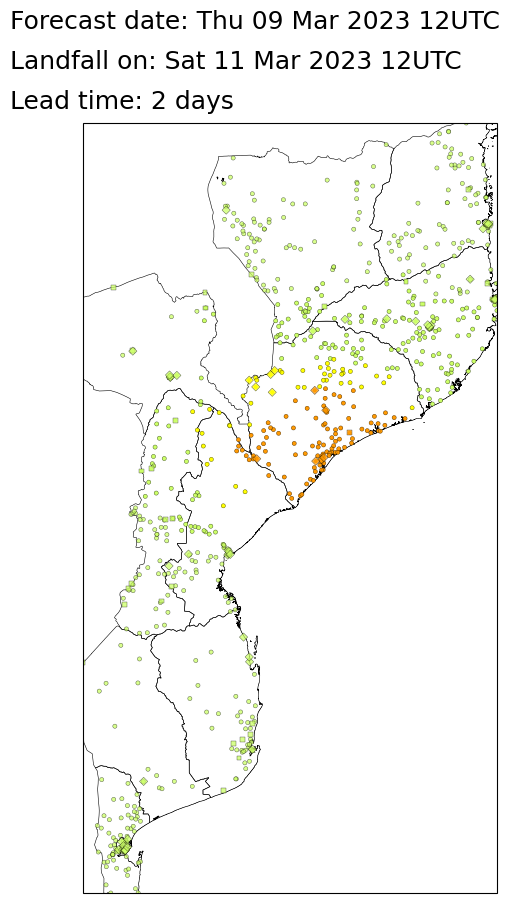

In [38]:
filename= "/cluster/home/gespejo/MOZ_struc_plots_Freddy/MOZ_20230309120000_trucimpforecast_nolegend_nocbar_imph2.jpg"
plotting_tracks_nolegend = plot_mimpact_nocbar_nolatlong_withtitle(ens_variables ['ens_FREDDY_20230309120000'],exp_longitude,exp_latitude,exp_impact,exp_levels,filename,
                                                0,gadm_MOZ,lead_time)

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from datetime import timedelta
import cartopy.crs as ccrs

def plot_tracks_gray_only(
    tc_tracks,
    figure_filename,
    gadm_cntry=None,
    lead_time=None,                  # int days or None
    region=None,                     # (min_lon, max_lon, min_lat, max_lat) or None to auto
    track_alpha=0.25,
    linestyle=':',
    linecolor='gray',
    figsize=(8, 8),
    dpi=1200,
):
    """
    Plot only TC tracks in gray; no exposure/impact points.
    No ticks/labels/grid. Optionally add titles and country outline.

    Parameters
    ----------
    tc_tracks : xarray-like with `.data` iterable of track objects
        Each track must expose .lon/.lat arrays and attrs['run_datetime'] on the first item.
    figure_filename : str
        Output image path.
    gadm_cntry : GeoDataFrame or None
        Optional boundary to overlay (plotted in black).
    lead_time : int or None
        Days lead time for the title; if None, titles are omitted.
    region : tuple or None
        (min_lon, max_lon, min_lat, max_lat). If None, inferred from tracks with small padding.
    """
    proj = ccrs.PlateCarree()

    # ---- extent (auto from tracks if not provided) ----
    if region is None:
        all_lon = np.concatenate([np.asarray(tr.lon) for tr in tc_tracks.data])
        all_lat = np.concatenate([np.asarray(tr.lat) for tr in tc_tracks.data])
        pad_x = max(0.5, 0.05 * (all_lon.max() - all_lon.min() or 1.0))
        pad_y = max(0.5, 0.05 * (all_lat.max() - all_lat.min() or 1.0))
        extent = (float(all_lon.min() - pad_x), float(all_lon.max() + pad_x),
                  float(all_lat.min() - pad_y), float(all_lat.max() + pad_y))
    else:
        extent = (region[0], region[1], region[2], region[3])

    mid_lon = 0.5 * (extent[0] + extent[1])

    # ---- figure/axis ----
    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    ax.set_extent(extent, crs=proj)

    # ---- plot tracks (gray) ----
    for track in tc_tracks.data:
        lonlat = np.stack([np.asarray(track.lon), np.asarray(track.lat)], axis=-1)
        # normalize longitudes around the plot center to avoid wrap artifacts
        lon = lonlat[:, 0]
        lon = ((lon - mid_lon + 180) % 360) - 180 + mid_lon
        lonlat[:, 0] = lon

        # build segments and drop those that would cross the edge
        segs = np.stack([lonlat[:-1], lonlat[1:]], axis=1)
        segs = segs[(segs[:, 0, 0] * segs[:, 1, 0]) >= 0]  # simple anti-meridian guard

        lc = LineCollection(segs, colors=linecolor, linestyle=linestyle, alpha=track_alpha, linewidths=1.0)
        lc.set_transform(proj)
        ax.add_collection(lc)

    # ---- country boundary (optional) ----
    if gadm_cntry is not None:
        gadm_cntry.plot(ax=ax, facecolor='none', edgecolor='black', linewidth=0.6, transform=proj)

    # ---- remove all axis decoration ----
    ax.set_axis_off()
    try:
        ax.outline_patch.set_visible(False)
    except Exception:
        pass

    # ---- optional titles above the figure ----
    if lead_time is not None and getattr(tc_tracks.data[0].attrs, 'get', None) is None:
        # tracks.attrs might be a dict; support common access pattern
        run_datetime = tc_tracks.data[0].attrs['run_datetime']
        event_time = run_datetime + timedelta(days=int(lead_time))
        plt.figtext(0.30, 1.02, f"Forecast date: {run_datetime:%a %d %b %Y %HUTC}",
                    color='black', fontsize=16, ha='left')
        plt.figtext(0.30, 0.98, f"Landfall on: {event_time:%a %d %b %Y %HUTC}",
                    color='black', fontsize=16, ha='left')
        plt.figtext(0.30, 0.94, f"Lead time: {lead_time} days",
                    color='black', fontsize=16, ha='left')

    plt.tight_layout()
    plt.savefig(figure_filename, bbox_inches='tight', dpi=dpi, pad_inches=0.1)

In [27]:
filename= "/cluster/home/gespejo/MOZ_struc_plots_Freddy/MOZ_tracks.jpg"

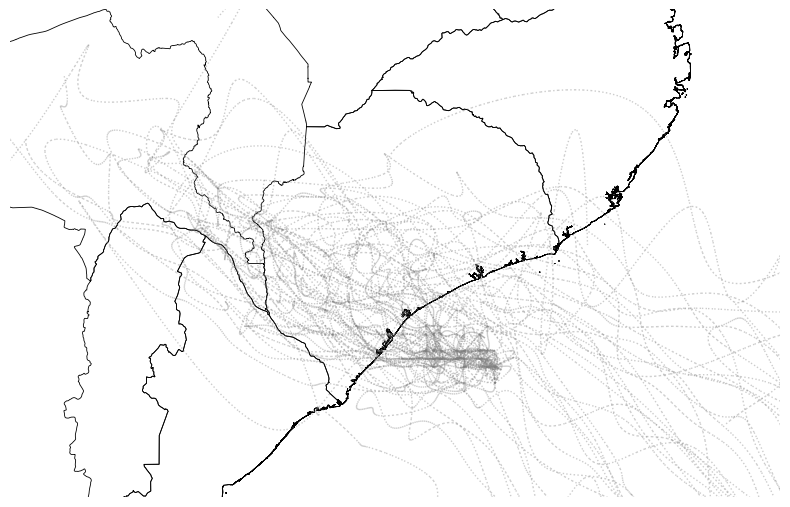

In [32]:
plot_tracks_gray_only(
    ens_variables ['ens_FREDDY_20230310120000'],
    filename,
    gadm_cntry=gadm_MOZ,
    lead_time=0,                      # or None to omit titles
    region=(32, 42, -20, -14),        # optional
    track_alpha=0.40
)